# HW7 Mini Project — Your IFR Interpolator

Design your own interpolator. For compatible data, it should be continuous, pass through the
supplied IFR points, and be **monotone and convex within the node interval**. Explain your choice
of method and how you handle data that cannot satisfy all these conditions.

You may consult **Hagan and West's method** for inspiration.

### My method — clipped monotone-convex piecewise quadratic

**Class:** `Interpolator1DMonotoneConvex` in `fixedincomelib/utilities/numerics.py`.

On each node interval $[x_i, x_{i+1}]$ with $h_i = x_{i+1}-x_i$, $u = (x-x_i)/h_i \in[0,1]$ and $\Delta_i = f_{i+1}-f_i$,

$$
f(x) = f_i + \Delta_i\big[(1-a_i)\,u + a_i\,u^2\big].
$$

| Requirement | Why it holds |
|---|---|
| Passes through the IFR points, continuous | $u=0 \Rightarrow f_i$, $u=1 \Rightarrow f_{i+1}$ for **any** $a_i$ |
| Monotone on the interval | $f'(x) = \frac{\Delta_i}{h_i}(1-a_i+2a_iu)$ has the sign of $\Delta_i$ whenever $\lvert a_i\rvert\le 1$ |
| Convex on the interval | $f''(x) = 2a_i\Delta_i/h_i^2 \ge 0 \iff a_i\Delta_i \ge 0$ |

So the admissible set is $a_i\in[0,1]$ for an increasing interval, $a_i\in[-1,0]$ for a decreasing one and $a_i=0$ for a flat one.
This is the same idea Hagan and West use. They pick a shape inside each interval and then **clip** it into the region (their "sectors") where it can't overshoot.

**Choosing $a_i$ (smoothness).** Node slopes $d_j$ come from the Fritsch–Butland weighted harmonic mean of the two neighbouring secant slopes $m_{j-1}, m_j$. It is set to $0$ at a local extremum of the data, and the end nodes use the one-sided secant.
The piece's end slopes are $m_i(1-a_i)$ and $m_i(1+a_i)$. A least-squares fit to $(d_i, d_{i+1})$ gives $a_i = (d_{i+1}-d_i)/(2m_i)$, which is then clipped into the admissible range.
**Convexity across nodes.** Hagan and West ask that the curve be "locally monotone and convex if the inputs show the analogous discrete properties". Wherever the data are locally convex ($m_{j-1}\le m_j$), the node slope satisfies $m_{j-1}\le d_j\le m_j$.
So I additionally cap the incoming slope at $d_j$ and floor the outgoing slope at $d_j$. This gives $f'(x_j^-)\le f'(x_j^+)$, and **convex data give a globally convex curve**, not just convex pieces. The caps always keep $a_i$ admissible.
For the supplied SOFR/FF data the secants increase (the data are convex), so both curves are globally convex. Left and right slopes at each node are close (e.g. 0.00213 vs 0.00226 at 9M), so the curve is continuous and nearly $C^1$.

**Data that cannot satisfy every condition.** Node-matching, continuity, and monotonicity and convexity inside each interval are treated as **hard** constraints. They can always be met, because the linear piece $a_i=0$ is always admissible.
What gets dropped is smoothness. If the data are concave (secants decrease) or turn around (a hump or a dip), no globally smooth curve can be monotone and convex on every interval. The clip then binds and the curve takes a **kink at the node** instead of overshooting the data or bending the wrong way. The verification cell below runs a humped and a decreasing data set to show this.

**Relation to Hagan & West (both supplied papers).** Their monotone-convex method takes *discrete* forwards $f_i^d$ (interval averages) and requires $\frac{1}{t_i-t_{i-1}}\int f = f_i^d$. Here the inputs are *point* IFR values that the curve must pass through, so I keep their framework but change the constraint.
I take their per-interval quadratic, their analysis of where the extremum falls, and the idea of clipping a shape parameter into the admissible sector, and I replace their averaging condition with node interpolation. The other criteria they list still hold:
* **positivity:** each piece stays between its two node values, so positive inputs give positive forwards;
* **continuity:** their unameliorated method is also only continuous ($C^0$) in their comparison table;
* **locality:** piece $i$ depends only on nodes $i-1,\dots,i+2$, so a bump to one input moves the curve only nearby;
* **stability:** forwards move at most proportionally to the inputs;
* **flat extrapolation beyond the last node.**

**Integration and extrapolation.** `integrate` is exact: on each piece the primitive is $h_i[f_iu + \Delta_i((1-a_i)u^2/2 + a_iu^3/3)]$, and outside the nodes it uses the extrapolated line. Discount factors $e^{-\int_0^T f}$ therefore carry no quadrature error.
FLAT extrapolation holds the end values, which also covers $[0, x_0]$ because the first node sits about 3 months after the value date. A single node (the funding curve) gives a constant curve.
The two optional gradient stubs are left as supplied.

### Implement your subclass

Write your class in `fixedincomelib/utilities/numerics.py`, inheriting from `Interpolator1D`.
Implement `interpolate` and `integrate`; leave the two optional gradient stubs as supplied.
The `MONOTONE_CONVEX` entry in `InterpMethod` and its factory mapping to
`Interpolator1DMonotoneConvex` are supplied. The one-node funding curve must be constant.

Each cell gives the product terms explicitly and calls the existing library APIs directly.
Within each pair, change only `'interpolation method'` from
`'PIECEWISE_CONSTANT_LEFT_CONTINUOUS'` to `'MONOTONE_CONVEX'`; rebuilding the model selects
your class. Compare the PVs and briefly explain the differences. Use `FLAT` extrapolation
and the supplied IFR data; no calibration is needed.

Cell 1 includes the shared imports and data. Run cells **1, 3, 5** for the PCP results;
after completing your implementation, restart the kernel and run all six.



In [1]:
import pandas as pd
from fixedincomelib import (
    qfCreateData1D, qfCreateDataCollection,
    qfCreateBuildMethod, qfCreateModelBuildMethodCollection, qfCreateModel,
    qfCreateProductFRA, qfCreateProductRFRSwap, qfCreateProductOvernightIndexBasisSwap,
    qfCreateValuationParameters, qfCreateValuationParametersCollection,
    qfCreateValueReport,
)

# Supplied IFR point values, in annual decimals.
node_dates = ["2026-04-02", "2026-10-02", "2027-07-02",
              "2028-01-03", "2029-01-02", "2031-01-02"]
sofr_quotes = pd.DataFrame({"values": [0.025, 0.026, 0.028, 0.030, 0.035, 0.047]}, index=node_dates)
ff_quotes = pd.DataFrame({"values": [0.023, 0.0237, 0.0252, 0.0265, 0.0305, 0.0405]}, index=node_dates)
funding_quotes = pd.DataFrame({"values": [0.0005]}, index=["2027-01-04"])
data_collection = qfCreateDataCollection([
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "SOFR-1B-IFR", sofr_quotes),
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "FF-1B-IFR", ff_quotes),
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "SOFR-1B-FUNDING-IFR", funding_quotes),
])
curve_inputs = [
    ("YIELD_CURVE_INDEX", {"TARGET": "SOFR-1B", "INSTANTANEOUS FORWARD RATE": "SOFR-1B-IFR"}),
    ("YIELD_CURVE_INDEX", {"TARGET": "FF-1B", "INSTANTANEOUS FORWARD RATE": "FF-1B-IFR"}),
    ("YIELD_CURVE_FUNDING", {"TARGET": "SOFR-1B-FLAT", "REFERENCE INDEX": "SOFR-1B",
                            "INSTANTANEOUS FORWARD RATE": "SOFR-1B-FUNDING-IFR"}),
]


/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
/opt/anaconda3/lib/python3.13/site-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


### Include an IFR curve plot and briefly explain how your method ensures monotonicity and convexity.

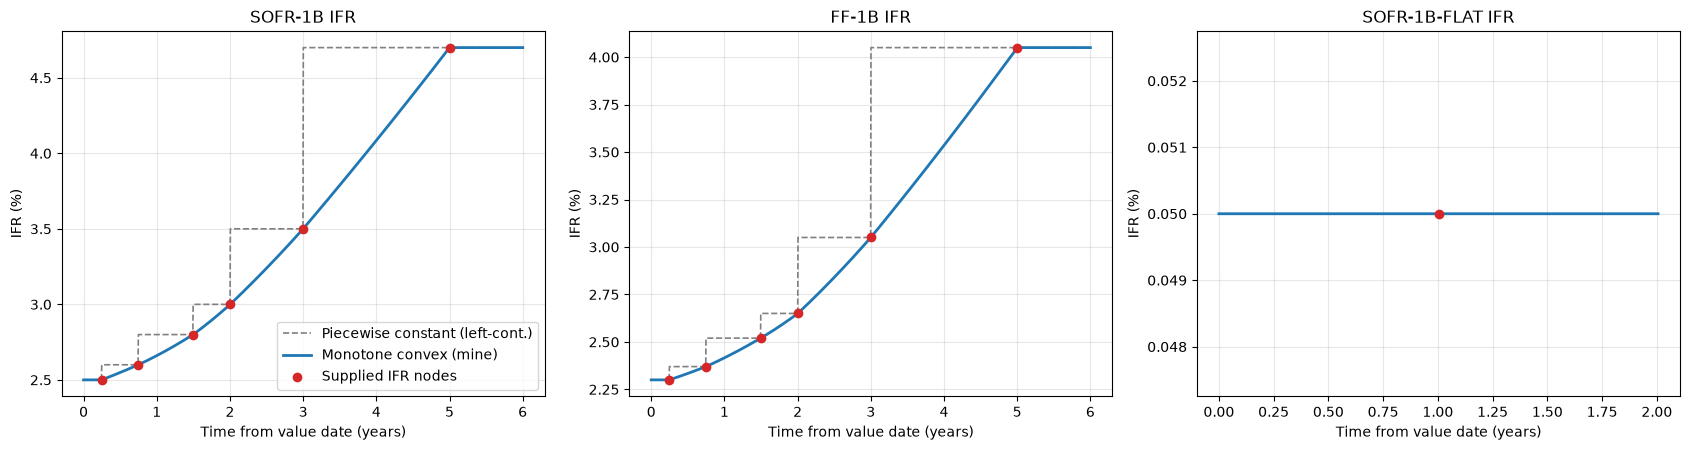

Node times (yrs): [0.2466 0.7479 1.4959 2.0027 3.     5.    ]
SOFR shape parameters a_i: [0.0673 0.1536 0.1048 0.0788 0.0493] (all in [0,1] -> increasing & convex pieces)


In [2]:
import numpy as np
import matplotlib.pyplot as plt

def build_curves(interp):
    bms = qfCreateModelBuildMethodCollection([
        qfCreateBuildMethod(kind, {**inputs, "INTERPOLATION METHOD": interp,
                                   "EXTRAPOLATION METHOD": "FLAT"})
        for kind, inputs in curve_inputs
    ])
    return qfCreateModel("2026-01-02", "YIELD_CURVE", data_collection, bms)

plot_models = {m: build_curves(m) for m in ["PIECEWISE_CONSTANT_LEFT_CONTINUOUS", "MONOTONE_CONVEX"]}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, idx in zip(axes, ["SOFR-1B", "FF-1B", "SOFR-1B-FLAT"]):
    mc = plot_models["MONOTONE_CONVEX"].retrieve_model_component(idx).state_data_interpolator
    pcp = plot_models["PIECEWISE_CONSTANT_LEFT_CONTINUOUS"].retrieve_model_component(idx).state_data_interpolator
    t_grid = np.linspace(0.0, max(mc.axis1[-1] + 1.0, 2.0), 1500)
    ax.plot(t_grid, [100 * pcp.interpolate(t) for t in t_grid], lw=1.2, ls="--", color="grey",
            label="Piecewise constant (left-cont.)")
    ax.plot(t_grid, [100 * mc.interpolate(t) for t in t_grid], lw=2, color="C0", label="Monotone convex (mine)")
    ax.scatter(mc.axis1, 100 * np.asarray(mc.values), color="C3", zorder=5, label="Supplied IFR nodes")
    ax.set_title(f"{idx} IFR")
    ax.set_xlabel("Time from value date (years)")
    ax.set_ylabel("IFR (%)")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()

sofr_mc = plot_models["MONOTONE_CONVEX"].retrieve_model_component("SOFR-1B").state_data_interpolator
print("Node times (yrs):", np.round(sofr_mc.axis1, 4))
print("SOFR shape parameters a_i:", np.round(sofr_mc.a_, 4), "(all in [0,1] -> increasing & convex pieces)")

**Reading the plot.** The monotone-convex curve hits every supplied point and rises without overshooting between consecutive nodes. Every SOFR and FF interval is increasing, so each piece uses $a_i\in[0,1]$: it starts flatter and steepens towards the next node, which is the convex shape.
Inside each interval the curve stays between the two node values, so it never creates a forward rate outside the range implied by the data.
The piecewise-constant curve is left-continuous, so on $(x_i, x_{i+1}]$ it already takes the **higher** right-hand value $f_{i+1}$. On a rising curve it therefore sits at or above the monotone-convex curve everywhere between nodes.
Beyond the last node (and before the first) both methods are FLAT, so they agree there. The funding curve has one node and is a constant 5 bp under both methods.

In [3]:
# Additional check: verify the required properties numerically (supplied + stress data).
from fixedincomelib.utilities.numerics import InterpolatorFactory, InterpMethod, ExtrapMethod

def verify(x, f, label):
    itp = InterpolatorFactory.create_1d_interpolator(list(x), list(f), InterpMethod.MONOTONE_CONVEX, ExtrapMethod.FLAT)
    node_err = max(abs(itp.interpolate(xi) - fi) for xi, fi in zip(x, f))
    mono, convex = True, True
    for i in range(len(x) - 1):
        ys = np.array([itp.interpolate(t) for t in np.linspace(x[i], x[i + 1], 2001)])
        mono &= bool(np.all(np.diff(ys) * np.sign(f[i + 1] - f[i]) >= -1e-15))
        convex &= bool(np.all(np.diff(ys, 2) >= -1e-15))
    slopes = [((itp.interpolate(xj) - itp.interpolate(xj - 1e-9)) / 1e-9,
               (itp.interpolate(xj + 1e-9) - itp.interpolate(xj)) / 1e-9) for xj in x[1:-1]]
    glob = all(l <= r + 1e-6 for l, r in slopes)
    tg = np.linspace(0.0, x[-1] + 1.0, 400001)
    quad = np.trapezoid([itp.interpolate(t) for t in tg], tg) if hasattr(np, "trapezoid") else np.trapz([itp.interpolate(t) for t in tg], tg)
    int_err = abs(itp.integrate(0.0, x[-1] + 1.0) - quad)
    print(f"{label:<28} max node error={node_err:.1e}  monotone={mono}  convex={convex}  globally convex={glob}  |exact-quadrature integral|={int_err:.1e}")

x_nodes = np.asarray(sofr_mc.axis1)
verify(x_nodes, sofr_quotes["values"].values, "SOFR (supplied)")
verify(x_nodes, ff_quotes["values"].values, "FF (supplied)")
verify(x_nodes, [0.03, 0.04, 0.035, 0.035, 0.02, 0.05], "Humped (stress)")
verify(x_nodes, [0.05, 0.04, 0.035, 0.034, 0.02, 0.01], "Decreasing/concave (stress)")
one = InterpolatorFactory.create_1d_interpolator([1.0], [0.0005], InterpMethod.MONOTONE_CONVEX, ExtrapMethod.FLAT)
print("One-node curve constant:", one.interpolate(0.0) == one.interpolate(10.0) == 0.0005,
      "| integral 0->2:", one.integrate(0.0, 2.0))

SOFR (supplied)              max node error=0.0e+00  monotone=True  convex=True  globally convex=True  |exact-quadrature integral|=4.6e-14


FF (supplied)                max node error=0.0e+00  monotone=True  convex=True  globally convex=True  |exact-quadrature integral|=4.7e-14


Humped (stress)              max node error=0.0e+00  monotone=True  convex=True  globally convex=False  |exact-quadrature integral|=1.9e-13


Decreasing/concave (stress)  max node error=0.0e+00  monotone=True  convex=True  globally convex=False  |exact-quadrature integral|=1.9e-13
One-node curve constant: True | integral 0->2: 0.001


In [4]:
# 1. FRA — piecewise constant
fra_pcp_convention = {
    'effective date': '2026-05-05',
    'termination date': '2026-11-05',
    'projection index': 'SOFR-1B',
    'fixed rate': 0.032,
    'notional': 1000000,
    'pay or receive': 'receive',
    'accrual basis': 'ACT/360',
    'business day convention': 'F',
    'holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": fra_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": fra_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
fra_pcp_model = qfCreateModel(
    fra_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
fra_pcp_product = qfCreateProductFRA(
    effective_date=fra_pcp_convention['effective date'],
    term_or_termination_date=fra_pcp_convention['termination date'],
    projection_index=fra_pcp_convention['projection index'],
    fixed_rate=fra_pcp_convention['fixed rate'],
    notional=fra_pcp_convention['notional'],
    pay_or_rec=fra_pcp_convention['pay or receive'],
    accrual_basis=fra_pcp_convention['accrual basis'],
    business_day_convention=fra_pcp_convention['business day convention'],
    holiday_convention=fra_pcp_convention['holiday convention'],
)
fra_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": fra_pcp_convention["funding index"],
    }),
])
fra_pcp_pv = qfCreateValueReport(fra_pcp_model, fra_pcp_product, fra_pcp_parameters, "PV")[0][1]
print("FRA | PCP PV:", fra_pcp_pv)


FRA | PCP PV: 2908.2866392379638


In [5]:
# 2. FRA — your interpolator
fra_student_convention = {
    'effective date': '2026-05-05',
    'termination date': '2026-11-05',
    'projection index': 'SOFR-1B',
    'fixed rate': 0.032,
    'notional': 1000000,
    'pay or receive': 'receive',
    'accrual basis': 'ACT/360',
    'business day convention': 'F',
    'holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": fra_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": fra_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
fra_student_model = qfCreateModel(
    fra_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
fra_student_product = qfCreateProductFRA(
    effective_date=fra_student_convention['effective date'],
    term_or_termination_date=fra_student_convention['termination date'],
    projection_index=fra_student_convention['projection index'],
    fixed_rate=fra_student_convention['fixed rate'],
    notional=fra_student_convention['notional'],
    pay_or_rec=fra_student_convention['pay or receive'],
    accrual_basis=fra_student_convention['accrual basis'],
    business_day_convention=fra_student_convention['business day convention'],
    holiday_convention=fra_student_convention['holiday convention'],
)
fra_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": fra_student_convention["funding index"],
    }),
])
fra_student_pv = qfCreateValueReport(fra_student_model, fra_student_product, fra_student_parameters, "PV")[0][1]
print("FRA | Student PV:", fra_student_pv)
print("Student minus PCP:", fra_student_pv - fra_pcp_pv)


FRA | Student PV: 3256.426205285865
Student minus PCP: 348.1395660479011


In [6]:
# 3. RFR swap — piecewise constant
swap_pcp_convention = {
    'effective date': '2026-04-02',
    'termination date': '2029-04-02',
    'overnight index': 'SOFR-1B',
    'fixed rate': 0.034,
    'notional': 1000000,
    'pay or receive': 'receive',
    'fixed accrual period': '1Y',
    'floating accrual period': '1Y',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'floating spread': 0.0,
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": swap_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": swap_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
swap_pcp_model = qfCreateModel(
    swap_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
swap_pcp_product = qfCreateProductRFRSwap(
    effective_date=swap_pcp_convention['effective date'],
    term_or_termination_date=swap_pcp_convention['termination date'],
    on_index=swap_pcp_convention['overnight index'],
    fixed_rate=swap_pcp_convention['fixed rate'],
    notional=swap_pcp_convention['notional'],
    pay_or_rec=swap_pcp_convention['pay or receive'],
    accrual_period=swap_pcp_convention['fixed accrual period'],
    floating_leg_accrual_period=swap_pcp_convention['floating accrual period'],
    accrual_basis=swap_pcp_convention['accrual basis'],
    compounding_method=swap_pcp_convention['compounding method'],
    spread=swap_pcp_convention['floating spread'],
    payment_off_set=swap_pcp_convention['payment offset'],
    pay_business_day_convention=swap_pcp_convention['payment business day convention'],
    pay_holiday_convention=swap_pcp_convention['payment holiday convention'],
)
swap_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": swap_pcp_convention["funding index"],
    }),
])
swap_pcp_pv = qfCreateValueReport(swap_pcp_model, swap_pcp_product, swap_pcp_parameters, "PV")[0][1]
print("RFR swap | PCP PV:", swap_pcp_pv)


RFR swap | PCP PV: 6222.517513069528


In [7]:
# 4. RFR swap — your interpolator
swap_student_convention = {
    'effective date': '2026-04-02',
    'termination date': '2029-04-02',
    'overnight index': 'SOFR-1B',
    'fixed rate': 0.034,
    'notional': 1000000,
    'pay or receive': 'receive',
    'fixed accrual period': '1Y',
    'floating accrual period': '1Y',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'floating spread': 0.0,
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": swap_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": swap_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
swap_student_model = qfCreateModel(
    swap_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
swap_student_product = qfCreateProductRFRSwap(
    effective_date=swap_student_convention['effective date'],
    term_or_termination_date=swap_student_convention['termination date'],
    on_index=swap_student_convention['overnight index'],
    fixed_rate=swap_student_convention['fixed rate'],
    notional=swap_student_convention['notional'],
    pay_or_rec=swap_student_convention['pay or receive'],
    accrual_period=swap_student_convention['fixed accrual period'],
    floating_leg_accrual_period=swap_student_convention['floating accrual period'],
    accrual_basis=swap_student_convention['accrual basis'],
    compounding_method=swap_student_convention['compounding method'],
    spread=swap_student_convention['floating spread'],
    payment_off_set=swap_student_convention['payment offset'],
    pay_business_day_convention=swap_student_convention['payment business day convention'],
    pay_holiday_convention=swap_student_convention['payment holiday convention'],
)
swap_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": swap_student_convention["funding index"],
    }),
])
swap_student_pv = qfCreateValueReport(swap_student_model, swap_student_product, swap_student_parameters, "PV")[0][1]
print("RFR swap | Student PV:", swap_student_pv)
print("Student minus PCP:", swap_student_pv - swap_pcp_pv)


RFR swap | Student PV: 12808.896661418621
Student minus PCP: 6586.379148349093


In [8]:
# 5. Overnight basis swap — piecewise constant
basis_pcp_convention = {
    'effective date': '2026-07-02',
    'termination date': '2028-07-03',
    'overnight index leg 1': 'SOFR-1B',
    'overnight index leg 2': 'FF-1B',
    'spread over leg 1': 0.001,
    'notional': 1000000,
    'pay or receive leg 1': 'receive',
    'accrual period leg 1': '3M',
    'accrual period leg 2': '3M',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": basis_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": basis_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
basis_pcp_model = qfCreateModel(
    basis_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
basis_pcp_product = qfCreateProductOvernightIndexBasisSwap(
    effective_date=basis_pcp_convention['effective date'],
    term_or_termination_date=basis_pcp_convention['termination date'],
    on_index_leg_1=basis_pcp_convention['overnight index leg 1'],
    on_index_leg_2=basis_pcp_convention['overnight index leg 2'],
    spread_over_leg_1=basis_pcp_convention['spread over leg 1'],
    notional=basis_pcp_convention['notional'],
    pay_or_rec_leg_1=basis_pcp_convention['pay or receive leg 1'],
    accrual_period_1=basis_pcp_convention['accrual period leg 1'],
    accrual_period_2=basis_pcp_convention['accrual period leg 2'],
    accrual_basis=basis_pcp_convention['accrual basis'],
    compounding_method=basis_pcp_convention['compounding method'],
    payment_off_set=basis_pcp_convention['payment offset'],
    pay_business_day_convention=basis_pcp_convention['payment business day convention'],
    pay_holiday_convention=basis_pcp_convention['payment holiday convention'],
)
basis_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": basis_pcp_convention["funding index"],
    }),
])
basis_pcp_pv = qfCreateValueReport(basis_pcp_model, basis_pcp_product, basis_pcp_parameters, "PV")[0][1]
print("Overnight basis swap | PCP PV:", basis_pcp_pv)


Overnight basis swap | PCP PV: 8351.348908181993


In [9]:
# 6. Overnight basis swap — your interpolator
basis_student_convention = {
    'effective date': '2026-07-02',
    'termination date': '2028-07-03',
    'overnight index leg 1': 'SOFR-1B',
    'overnight index leg 2': 'FF-1B',
    'spread over leg 1': 0.001,
    'notional': 1000000,
    'pay or receive leg 1': 'receive',
    'accrual period leg 1': '3M',
    'accrual period leg 2': '3M',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": basis_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": basis_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
basis_student_model = qfCreateModel(
    basis_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
basis_student_product = qfCreateProductOvernightIndexBasisSwap(
    effective_date=basis_student_convention['effective date'],
    term_or_termination_date=basis_student_convention['termination date'],
    on_index_leg_1=basis_student_convention['overnight index leg 1'],
    on_index_leg_2=basis_student_convention['overnight index leg 2'],
    spread_over_leg_1=basis_student_convention['spread over leg 1'],
    notional=basis_student_convention['notional'],
    pay_or_rec_leg_1=basis_student_convention['pay or receive leg 1'],
    accrual_period_1=basis_student_convention['accrual period leg 1'],
    accrual_period_2=basis_student_convention['accrual period leg 2'],
    accrual_basis=basis_student_convention['accrual basis'],
    compounding_method=basis_student_convention['compounding method'],
    payment_off_set=basis_student_convention['payment offset'],
    pay_business_day_convention=basis_student_convention['payment business day convention'],
    pay_holiday_convention=basis_student_convention['payment holiday convention'],
)
basis_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": basis_student_convention["funding index"],
    }),
])
basis_student_pv = qfCreateValueReport(basis_student_model, basis_student_product, basis_student_parameters, "PV")[0][1]
print("Overnight basis swap | Student PV:", basis_student_pv)
print("Student minus PCP:", basis_student_pv - basis_pcp_pv)


Overnight basis swap | Student PV: 7619.975194996572
Student minus PCP: -731.3737131854214


In [10]:
# Summary: PV comparison and average projected IFR over each product's accrual window
pcp_m = plot_models["PIECEWISE_CONSTANT_LEFT_CONTINUOUS"]
mc_m = plot_models["MONOTONE_CONVEX"]
def avg_bp(model, idx, a, b):
    return 1e4 * model.retrieve_model_component(idx).state_data_interpolator.integrate(a, b) / (b - a)
windows = {"FRA": (0.34, 0.85), "RFR swap": (0.25, 3.25), "Overnight basis swap": (0.50, 2.50)}
rows = []
for name, pcp_pv, mc_pv in [("FRA", fra_pcp_pv, fra_student_pv),
                            ("RFR swap", swap_pcp_pv, swap_student_pv),
                            ("Overnight basis swap", basis_pcp_pv, basis_student_pv)]:
    a, b = windows[name]
    rows.append({
        "Product": name, "PCP PV": pcp_pv, "Monotone-convex PV": mc_pv, "Diff (MC - PCP)": mc_pv - pcp_pv,
        "Avg SOFR IFR PCP (bp)": avg_bp(pcp_m, "SOFR-1B", a, b),
        "Avg SOFR IFR MC (bp)": avg_bp(mc_m, "SOFR-1B", a, b),
        "Avg FF IFR PCP (bp)": avg_bp(pcp_m, "FF-1B", a, b),
        "Avg FF IFR MC (bp)": avg_bp(mc_m, "FF-1B", a, b),
    })
pd.DataFrame(rows).set_index("Product").round(2)

,PCP PV,Monotone-convex PV,Diff (MC - PCP),Avg SOFR IFR PCP (bp),Avg SOFR IFR MC (bp),Avg FF IFR PCP (bp),Avg FF IFR MC (bp)
Product,,,,,,,
FRA,2908.29,3256.43,348.14,264.00,256.88,240.00,234.82
RFR swap,6222.52,12808.90,6586.38,319.16,296.02,282.08,263.69
Overnight basis swap,8351.35,7619.98,-731.37,299.99,283.62,266.61,254.12


### PV comparison — explanation

| Product (receive side) | PCP PV | Monotone-convex PV | Difference |
|---|---:|---:|---:|
| FRA (receive 3.20% fixed, May–Nov 2026) | 2,908.29 | 3,256.43 | **+348.14** |
| 3Y RFR swap (receive 3.40% fixed) | 6,222.52 | 12,808.90 | **+6,586.38** |
| 2Y SOFR/FF basis (receive SOFR + 10 bp) | 8,351.35 | 7,619.98 | **−731.37** |

**Why they differ.** The only change is the interpolation of the IFR between nodes. Both the SOFR and FF node values rise with maturity, and the PCP curve is *left-continuous*: on $(x_i, x_{i+1}]$ it already uses the **upper** value $f_{i+1}$.
On an upward-sloping curve it therefore puts the forward at the next (higher) node level for the whole interval. The monotone-convex curve climbs gradually from $f_i$ to $f_{i+1}$, starting flat and steepening, so between nodes it is always **below** PCP.
Projected forwards are therefore lower under my interpolator. Discount factors are slightly higher too, because the funding curve SOFR-1B-FLAT = SOFR-1B × a flat 5 bp spread. The projection effect dominates.

* **FRA (+348).** The average SOFR IFR over the accrual window falls by about 7 bp (264 → 257 bp). Receiving fixed against a lower floating rate is worth more: ≈ 7 bp × 1,000,000 × 0.51 yr ≈ 360, in line with +348.
* **RFR swap (+6,586, the largest).** The swap runs 3 years and covers the steepest part of the curve. The last quarter, 2029-01 → 2029-04, falls in the 3y–5y interval, where PCP already uses the 5y value of 4.70% while the monotone-convex curve is still near 3.5%. The average SOFR forward drops by about 23 bp (319 → 296 bp), and ≈ 23 bp × 3 yrs × 1,000,000 ≈ 6,900. The receive-fixed PV roughly doubles. Interpolation choice matters most for long-dated trades that span widely spaced, steep nodes.
* **Basis swap (−731).** Both legs are floating, so most of the effect cancels. The SOFR node increments are larger than the FF increments (SOFR 2.5% → 4.7%, FF 2.3% → 4.05%), so PCP over-states SOFR by more than it over-states FF. Under monotone-convex, the average SOFR forward falls about 16.4 bp and FF about 12.5 bp, so the received SOFR + 10 bp leg loses about 4 bp relative to the paid FF leg: ≈ 4 bp × 2 yrs × 1,000,000 ≈ 780, in line with −731.

**Takeaway.** PCP is simple but places each jump at the start of the interval, so on a rising curve it systematically biases forwards upward. The monotone-convex curve stays inside the node values, is continuous, globally convex for this data, (almost $C^1$ here) and gives forwards that are more realistic and stable. The price differences grow with trade length and with the steepness of the curve between widely spaced nodes.